# HAL-TMLE Right-Censored Target Learning

This notebook is the right-censored analogue of `examples/example_full_data_target_learning.ipynb`.

It does two things:

1. a single-target walkthrough driven by `TARGET_TYPE`
2. a batch demonstration and small Monte Carlo run across all four right-censored targets

The four targets are:

- `Survival`
- `RMST`
- `DensitySquare`
- `Entropy`

The demo uses the updated right-censored targeting defaults:

- censoring generated from `Unif[0, 1.2]`
- `CV-IPCW-L1MLE` as the initial estimator
- no cheat mode
- targeting `Gbar` truncated at order `1 / (sqrt(n) log n)`
- automatic targeting that checks the initial EIF score before taking any TMLE step


In [1]:
import sys
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

CANDIDATES = [
    pathlib.Path.cwd().resolve(),
    pathlib.Path('/Users/houyilong/GitHub/HALDensity/examples/HAL-TMLE-RC'),
]
for candidate in CANDIDATES:
    if (candidate / 'rc_target_learning_demo_utils.py').exists():
        NOTEBOOK_DIR = candidate
        break
else:
    raise FileNotFoundError('Could not find rc_target_learning_demo_utils.py')

ROOT = NOTEBOOK_DIR.parent.parent
for path in (ROOT, NOTEBOOK_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import rc_target_learning_demo_utils as demo


def _summarize_mc_mean_score(target_type, estimates):
    canonical = demo.normalize_target_type(target_type)
    coord_col = demo.target_coordinate_column(canonical) or 'target'
    score_rows = []
    stage_specs = [
        ('initial', 'eif_mean_initial_stage', 'exact_eif_mean_initial_stage'),
        ('one_step', 'eif_mean_one_step', 'exact_eif_mean_one_step'),
        ('final', 'eif_mean_final', 'exact_eif_mean_final'),
    ]

    for coord_value, group in estimates.groupby(coord_col, sort=True):
        for stage_label, implemented_col, exact_col in stage_specs:
            if implemented_col not in group.columns:
                continue
            score_col = exact_col if exact_col in group.columns else implemented_col
            values = group[score_col].to_numpy(dtype=float)
            row = {
                'stage': stage_label,
                'mean_score': float(np.nanmean(values)),
                'n_replicates': int(values.size),
            }
            row[coord_col] = coord_value
            score_rows.append(row)

    summary = pd.DataFrame(score_rows)
    if summary.empty:
        return summary

    stage_order = [
        stage for stage in ('initial', 'one_step', 'final') if stage in summary['stage'].unique()
    ]
    summary['stage'] = pd.Categorical(summary['stage'], categories=stage_order, ordered=True)
    if demo.target_coordinate_column(canonical) is not None:
        return summary.sort_values([coord_col, 'stage']).reset_index(drop=True)
    return summary.sort_values(['stage']).reset_index(drop=True)


def _summarize_all_target_mc_mean_score(mc_result):
    score_tables = []
    for target_type in demo.TARGET_OPTIONS:
        if target_type not in mc_result['by_target']:
            continue
        score_summary = _summarize_mc_mean_score(
            target_type,
            mc_result['by_target'][target_type]['estimates'],
        )
        if score_summary.empty:
            continue
        score_summary.insert(0, 'target_type', target_type)
        score_tables.append(score_summary)
    if len(score_tables) == 0:
        return pd.DataFrame()
    return pd.concat(score_tables, ignore_index=True)


def _summarize_targeting_usage(mc_result):
    usage_rows = []
    for target_type in demo.TARGET_OPTIONS:
        if target_type not in mc_result['by_target']:
            continue
        estimates = mc_result['by_target'][target_type]['estimates'].copy()
        if estimates.empty or 'n_iterations' not in estimates.columns:
            continue

        canonical = demo.normalize_target_type(target_type)
        coord_col = demo.target_coordinate_column(canonical) or 'target'
        if coord_col not in estimates.columns:
            estimates[coord_col] = canonical

        for coord_value, group in estimates.groupby(coord_col, sort=True):
            n_seeds = int(group['replicate'].nunique())
            n_iterations = pd.to_numeric(group['n_iterations'], errors='coerce').fillna(0.0)
            if 'stop_reason' in group.columns:
                stop_reason = group['stop_reason'].astype(str)
            else:
                stop_reason = pd.Series([''] * len(group), index=group.index, dtype=object)

            n_targeted = int(np.sum(n_iterations > 0.0))
            n_skipped_initial_gate = int(np.sum(stop_reason == 'initial_score_tolerance'))
            usage_rows.append(
                {
                    'target_type': target_type,
                    'coordinate': coord_col,
                    'coordinate_value': coord_value,
                    'n_seeds': n_seeds,
                    'n_targeted': n_targeted,
                    'n_skipped_initial_gate': n_skipped_initial_gate,
                    'targeted_rate': float(n_targeted / n_seeds) if n_seeds > 0 else float('nan'),
                    'mean_n_iterations': float(np.nanmean(n_iterations.to_numpy(dtype=float))),
                }
            )

    usage = pd.DataFrame(usage_rows)
    if usage.empty:
        return usage

    return usage.sort_values(['target_type', 'coordinate', 'coordinate_value']).reset_index(drop=True)


def _summarize_survival_positivity_issues(mc_result):
    if 'Survival' not in mc_result['by_target']:
        return pd.DataFrame()

    estimates = mc_result['by_target']['Survival']['estimates'].copy()
    if estimates.empty or not {'replicate', 't0'}.issubset(estimates.columns):
        return pd.DataFrame()

    if 'survival_positivity_issue' in estimates.columns:
        positivity_issue = estimates['survival_positivity_issue'].astype(bool)
    elif 'positivity_eic_excluded_count_final' in estimates.columns:
        positivity_issue = (
            pd.to_numeric(estimates['positivity_eic_excluded_count_final'], errors='coerce').fillna(0.0)
            > 0.0
        )
    elif 'clip_active_eic_excluded_count_final' in estimates.columns:
        positivity_issue = (
            pd.to_numeric(estimates['clip_active_eic_excluded_count_final'], errors='coerce').fillna(0.0)
            > 0.0
        )
    else:
        return pd.DataFrame()

    if 'survival_gbar_t0_clipped' in estimates.columns:
        t0_clip = estimates['survival_gbar_t0_clipped'].astype(bool)
    else:
        t0_clip = pd.Series(False, index=estimates.index)

    if 'survival_n_jump_terms_clipped' in estimates.columns:
        jump_clip = (
            pd.to_numeric(estimates['survival_n_jump_terms_clipped'], errors='coerce').fillna(0.0)
            > 0.0
        )
    else:
        jump_clip = pd.Series(False, index=estimates.index)

    estimates = estimates.assign(
        _positivity_issue=positivity_issue,
        _t0_clip=t0_clip,
        _jump_clip=jump_clip,
    )

    rows = []
    for t0, group in estimates.groupby('t0', sort=True):
        n_seeds = int(group['replicate'].nunique())
        n_issue = int(np.sum(group['_positivity_issue'].to_numpy(dtype=bool)))
        n_t0_clip = int(np.sum(group['_t0_clip'].to_numpy(dtype=bool)))
        n_jump_clip = int(np.sum(group['_jump_clip'].to_numpy(dtype=bool)))
        rows.append(
            {
                't0': float(t0),
                'n_seeds': n_seeds,
                'n_with_positivity_issue': n_issue,
                'positivity_issue_rate': float(n_issue / n_seeds) if n_seeds > 0 else float('nan'),
                'n_with_t0_gbar_clipping': n_t0_clip,
                'n_with_jump_gbar_clipping': n_jump_clip,
            }
        )

    return pd.DataFrame(rows).sort_values(['t0']).reset_index(drop=True)


/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ============================
# CONFIGURE TARGET LEARNER HERE
# ============================
# Choose one: "Survival", "RMST", "DensitySquare", "Entropy"

TARGET_TYPE = 'Survival'
TARGET_GRID = demo.default_target_grid(9)

N_OBS = 400
DATA_SEED = 18

SIMULATION_KWARGS = dict(demo.DEFAULT_SIMULATION_KWARGS)
# Switch the event-time DGP here if desired.
# Example:
SIMULATION_KWARGS.update({
    'event_dist': 'truncnorm',
    'event_truncnorm_mean': 0.5,
    'event_truncnorm_sd': 0.15,
})

INITIAL_FIT_KWARGS = {
    'cv_folds': 5,
    'n_trials': 50,
    'random_state': DATA_SEED,
    'n_grid_points': 100,
    'stage1_param_overrides': {
        **demo.DEFAULT_STAGE1_PARAM_OVERRIDES,
        'basis_order': [1, 2],
        'norm_constraint': {'low': 3.0, 'high': 200.0, 'log': False},
    },
    'stage1_tuner_kwargs': dict(demo.DEFAULT_STAGE1_TUNER_KWARGS),
    'norm_constraint_factors': [1.0],
    'l1_kwargs': dict(demo.DEFAULT_L1_KWARGS),
    'no_undersmoothing_factor': 1.0,
}

TARGETING_OPTIONS = dict(demo.DEFAULT_TARGETING_OPTIONS)
TARGETING_OPTIONS.update({
    'mode': 'auto',
    'store_pointwise_arrays': False,
    'targeting_gbar_floor_scale': 5.0,
})

MC_REPS = 100
MC_N = 400
MC_BASE_SEED = 3000
MC_N_WORKERS = 8
MC_SHOW_PROGRESS = True
MC_INITIAL_FIT_KWARGS = {
    'cv_folds': 5,
    'n_trials': 50,
    'n_grid_points': 100,
    'stage1_param_overrides': {
        **demo.DEFAULT_STAGE1_PARAM_OVERRIDES,
        'basis_order': [1, 2],
        'norm_constraint': {'low': 3.0, 'high': 200.0, 'log': False},
    },
    'stage1_tuner_kwargs': dict(demo.DEFAULT_STAGE1_TUNER_KWARGS),
    'norm_constraint_factors': [1.0],
    'l1_kwargs': {
        **demo.DEFAULT_L1_KWARGS,
        'n_grid_points': 100,
        'n_iterations': 1000,
        'history_every': 20,
    },
    'no_undersmoothing_factor': 1.0,
}

RUN_ALL_TARGET_DEMOS = True
RUN_ALL_TARGET_MC = True

print(f'TARGET_TYPE = {TARGET_TYPE}')
print('Shared Survival/RMST grid:', np.round(TARGET_GRID, 3))
print(f'RUN_ALL_TARGET_DEMOS = {RUN_ALL_TARGET_DEMOS}')
print(f'RUN_ALL_TARGET_MC = {RUN_ALL_TARGET_MC}')
print(f'MC_N_WORKERS = {MC_N_WORKERS}')
print(f'MC_SHOW_PROGRESS = {MC_SHOW_PROGRESS}')


TARGET_TYPE = Survival
Shared Survival/RMST grid: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
RUN_ALL_TARGET_DEMOS = True
RUN_ALL_TARGET_MC = True
MC_N_WORKERS = 8
MC_SHOW_PROGRESS = True


## One Data Set

The next cells simulate one right-censored data set, fit the `CV-IPCW-L1MLE` initializer once, and then reuse that fit for both the selected target and the batch all-target comparison.


In [3]:
sim = demo.simulate_demo_data(
    n=N_OBS,
    seed=DATA_SEED,
    **SIMULATION_KWARGS,
)
observed_data = sim['observed_data']
truth = sim['truth']

display(pd.DataFrame([sim['diagnostics']]))
display(observed_data.head())


,n_observations,uncensored_rate,censoring_rate,event_dist,truth_name,censor_low,censor_high,event_truncnorm_mean,event_truncnorm_sd
0,400,0.61,0.39,truncnorm,"TruncNorm(mean=0.5, sd=0.15) event time on [0, 1]",0.0,1.2,0.5,0.15


,T,Delta
0,0.461762,1
1,0.586194,1
2,0.136071,0
3,0.292306,1
4,0.743605,0


In [4]:
initial_fit = demo.fit_cv_ipcw_l1mle_initial(
    observed_data,
    evaluation_grid=TARGET_GRID,
    **INITIAL_FIT_KWARGS,
)

initial_summary = pd.DataFrame([
    {
        'selected_norm_factor': initial_fit['selected_norm_factor'],
        'selected_norm_constraint': initial_fit['selected_norm_constraint'],
        'runtime_seconds': initial_fit['runtime_seconds'],
    }
])

display(initial_summary)
display(initial_fit['path_df'])


/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


,selected_norm_factor,selected_norm_constraint,runtime_seconds
0,1.0,30.403325,7.3056


,norm_factor,norm_constraint,runtime_seconds,observed_loglik,n_iterations_run,converged,support_size
0,1.0,30.403325,0.003531,79.760476,18,True,9


## Single-Target Walkthrough


In [5]:
single_demo = demo.run_demo_for_target(
    TARGET_TYPE,
    sim=sim,
    initial_fit=initial_fit,
    shared_grid=TARGET_GRID,
    targeting_options=TARGETING_OPTIONS,
)

targeted_fit = single_demo['targeted_fit']
augmented_summary = single_demo['augmented_summary']

display(single_demo['display_summary'])


,t0,truth,psi_km,psi_init,psi_one_step,psi_final,km_bias,plugin_bias,targeted_bias,eif_mean_final,exact_eif_mean_final,exact_minus_implemented_eif_mean_final,threshold_final,exact_threshold_final,passes_initial_threshold,status_one_step,n_iterations,stop_reason
0,0.1,0.996596,0.994673,0.992211,0.994671,0.994671,-0.001923,-0.004384,-0.001925,-1.452340e-07,-1.452340e-07,-1.887379e-16,0.000628,0.000628,False,score_tolerance,1,score_tolerance
1,0.2,0.977660,0.980052,0.969093,0.979776,0.979776,0.002393,-0.008567,0.002117,-1.700815e-06,-1.700815e-06,-8.715249e-17,0.001249,0.001249,False,score_tolerance,1,score_tolerance
2,0.3,0.909140,0.906379,0.900471,0.908178,0.908178,-0.002761,-0.008669,-0.000962,-7.723284e-06,-7.723284e-06,2.220446e-16,0.002680,0.002680,False,score_tolerance,1,score_tolerance
3,0.4,0.747720,0.724687,0.733721,0.721803,0.721803,-0.023033,-0.013999,-0.025917,3.422498e-05,3.422498e-05,8.883682e-18,0.004385,0.004385,False,score_tolerance,1,score_tolerance
4,0.5,0.500000,0.522733,0.504994,0.519506,0.519506,0.022733,0.004994,0.019506,-5.376077e-06,-5.376077e-06,1.665267e-18,0.005107,0.005107,False,score_tolerance,1,score_tolerance
5,0.6,0.252280,0.214496,0.235060,0.210608,0.210608,-0.037784,-0.017220,-0.041672,1.637032e-04,1.637032e-04,7.104235e-17,0.004412,0.004412,False,score_tolerance,1,score_tolerance
6,0.7,0.090860,0.088950,0.094608,0.089562,0.089562,-0.001910,0.003748,-0.001298,2.841587e-07,2.841587e-07,4.440888e-18,0.003200,0.003200,False,score_tolerance,1,score_tolerance
7,0.8,0.022340,0.048923,0.035434,0.048681,0.048681,0.026582,0.013094,0.026341,4.249835e-04,4.249835e-04,2.818926e-18,0.002563,0.002563,False,score_tolerance,1,score_tolerance
8,0.9,0.003404,0.012231,0.010504,0.012229,0.012229,0.008826,0.007099,0.008825,1.718725e-05,1.718725e-05,5.549760e-18,0.001405,0.001405,False,score_tolerance,1,score_tolerance


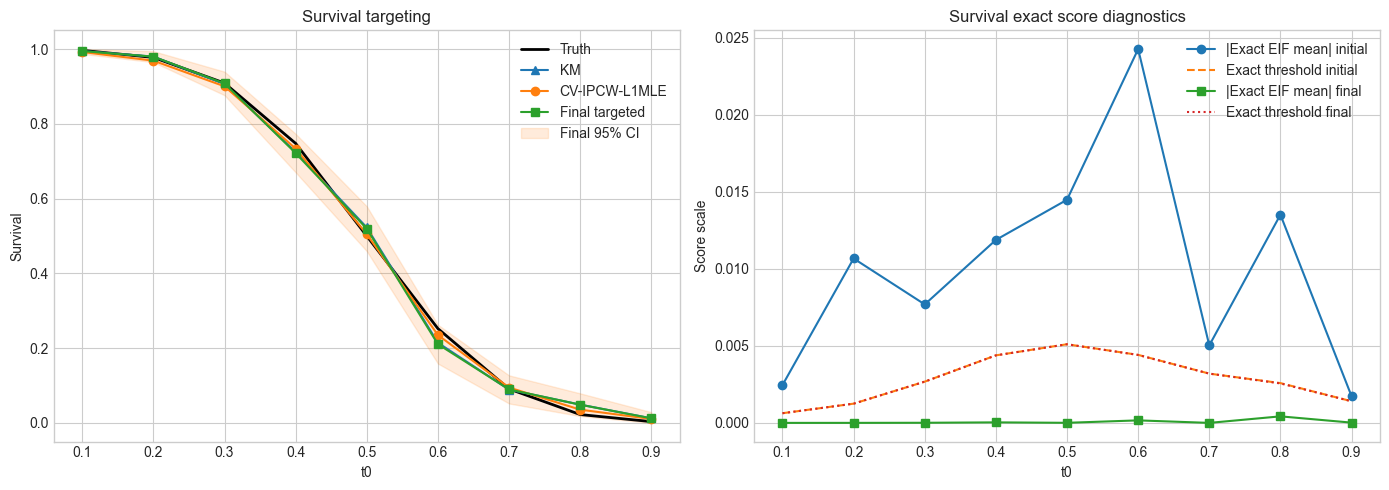

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
demo.plot_target_estimates(TARGET_TYPE, augmented_summary, ax=axes[0])
demo.plot_score_diagnostics(TARGET_TYPE, augmented_summary, ax=axes[1])
plt.tight_layout()
plt.show()


## Single-Target Monte Carlo Check

This is the original small MC check for the currently selected target.


In [7]:
if MC_REPS <= 0:
    mc_result = None
    print('Set MC_REPS > 0 to run the small Monte Carlo check.')
else:
    mc_result = demo.run_small_mc(
        TARGET_TYPE,
        n_reps=MC_REPS,
        n=MC_N,
        base_seed=MC_BASE_SEED,
        target_grid=demo.target_grid_for_type(TARGET_TYPE, shared_grid=TARGET_GRID),
        simulation_kwargs=SIMULATION_KWARGS,
        initial_fit_kwargs=MC_INITIAL_FIT_KWARGS,
        targeting_options=TARGETING_OPTIONS,
        n_workers=MC_N_WORKERS,
        show_progress=MC_SHOW_PROGRESS,
    )
    display(mc_result['metrics'])
    display(_summarize_mc_mean_score(mc_result['metadata']['target_type'], mc_result['estimates']))


Survival MC:   0%|          | 0/100 [00:00<?, ?it/s]/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjus

,stage,truth,mean_estimate,bias,variance,mse,oracle_sd,oracle_coverage,n_replicates,t0
0,km,0.996596,0.996212,-0.000384,0.000009,0.000009,0.003001,0.95,100,0.1
1,initial,0.996596,0.984680,-0.011916,0.000524,0.000661,0.022893,0.87,100,0.1
2,final,0.996596,0.996330,-0.000266,0.000009,0.000009,0.002956,0.96,100,0.1
3,km,0.977660,0.977220,-0.000440,0.000055,0.000054,0.007405,0.93,100,0.2
4,initial,0.977660,0.955223,-0.022436,0.001950,0.002434,0.044162,0.87,100,0.2
5,final,0.977660,0.977602,-0.000057,0.000053,0.000053,0.007293,0.93,100,0.2
6,km,0.909140,0.911832,0.002692,0.000222,0.000227,0.014915,0.94,100,0.3
7,initial,0.909140,0.884909,-0.024231,0.002926,0.003484,0.054095,0.87,100,0.3
8,final,0.909140,0.912780,0.003641,0.000213,0.000224,0.014593,0.94,100,0.3
9,km,0.747720,0.747708,-0.000012,0.000565,0.000559,0.023764,0.94,100,0.4


,stage,mean_score,n_replicates,t0
0,initial,0.011663,100,0.1
1,one_step,0.000013,100,0.1
2,final,0.000013,100,0.1
3,initial,0.022383,100,0.2
4,one_step,0.000008,100,0.2
5,final,0.000008,100,0.2
6,initial,0.027828,100,0.3
7,one_step,-0.000033,100,0.3
8,final,-0.000033,100,0.3
9,initial,0.014961,100,0.4


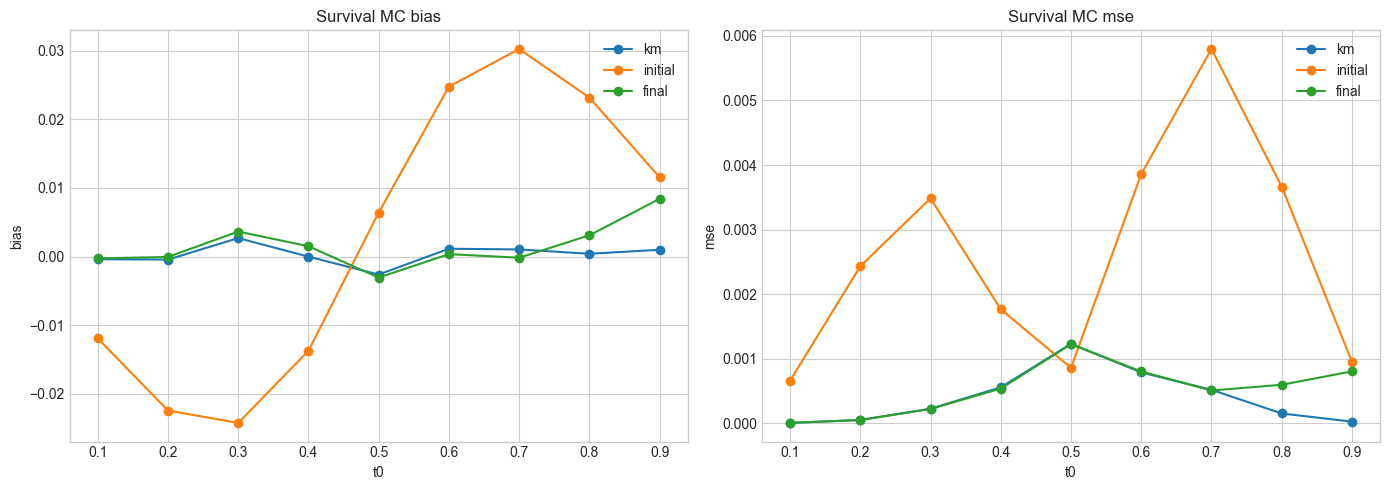

In [8]:
if mc_result is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    demo.plot_mc_metrics(TARGET_TYPE, mc_result['metrics'], metric='bias', ax=axes[0])
    demo.plot_mc_metrics(TARGET_TYPE, mc_result['metrics'], metric='mse', ax=axes[1])
    plt.tight_layout()
    plt.show()


## All Four Target Demos

This section reuses the same one-data-set fit and runs all four targeters side by side.


In [9]:
all_target_demo = None
if RUN_ALL_TARGET_DEMOS:
    all_target_options = dict(TARGETING_OPTIONS)
    all_target_options['store_pointwise_arrays'] = True
    all_target_demo = demo.run_all_target_demos(
        sim=sim,
        initial_fit=initial_fit,
        shared_grid=TARGET_GRID,
        targeting_options=all_target_options,
    )
    display(demo.combine_demo_display_summaries(all_target_demo))
else:
    print('Set RUN_ALL_TARGET_DEMOS = True to run the batch demo section.')


,target_type,t0,truth,psi_km,psi_init,psi_one_step,psi_final,km_bias,plugin_bias,targeted_bias,eif_mean_final,exact_eif_mean_final,exact_minus_implemented_eif_mean_final,threshold_final,exact_threshold_final,passes_initial_threshold,status_one_step,n_iterations,stop_reason,tau
0,Survival,0.1,0.996596,0.994673,0.992211,0.994671,0.994671,-0.001923,-0.004384,-0.001925,-1.452340e-07,-1.452340e-07,-1.887379e-16,0.000628,0.000628,False,score_tolerance,1,score_tolerance,NaN
1,Survival,0.2,0.977660,0.980052,0.969093,0.979776,0.979776,0.002393,-0.008567,0.002117,-1.700815e-06,-1.700815e-06,-8.715249e-17,0.001249,0.001249,False,score_tolerance,1,score_tolerance,NaN
2,Survival,0.3,0.909140,0.906379,0.900471,0.908178,0.908178,-0.002761,-0.008669,-0.000962,-7.723284e-06,-7.723284e-06,2.220446e-16,0.002680,0.002680,False,score_tolerance,1,score_tolerance,NaN
3,Survival,0.4,0.747720,0.724687,0.733721,0.721803,0.721803,-0.023033,-0.013999,-0.025917,3.422498e-05,3.422498e-05,8.883682e-18,0.004385,0.004385,False,score_tolerance,1,score_tolerance,NaN
4,Survival,0.5,0.500000,0.522733,0.504994,0.519506,0.519506,0.022733,0.004994,0.019506,-5.376077e-06,-5.376077e-06,1.665267e-18,0.005107,0.005107,False,score_tolerance,1,score_tolerance,NaN
5,Survival,0.6,0.252280,0.214496,0.235060,0.210608,0.210608,-0.037784,-0.017220,-0.041672,1.637032e-04,1.637032e-04,7.104235e-17,0.004412,0.004412,False,score_tolerance,1,score_tolerance,NaN
6,Survival,0.7,0.090860,0.088950,0.094608,0.089562,0.089562,-0.001910,0.003748,-0.001298,2.841587e-07,2.841587e-07,4.440888e-18,0.003200,0.003200,False,score_tolerance,1,score_tolerance,NaN
7,Survival,0.8,0.022340,0.048923,0.035434,0.048681,0.048681,0.026582,0.013094,0.026341,4.249835e-04,4.249835e-04,2.818926e-18,0.002563,0.002563,False,score_tolerance,1,score_tolerance,NaN
8,Survival,0.9,0.003404,0.012231,0.010504,0.012229,0.012229,0.008826,0.007099,0.008825,1.718725e-05,1.718725e-05,5.549760e-18,0.001405,0.001405,False,score_tolerance,1,score_tolerance,NaN
9,RMST,NaN,0.099882,0.099928,0.099679,0.099893,0.099929,0.000046,-0.000203,0.000046,-1.353713e-10,-1.353713e-10,-6.665675e-18,0.000010,0.000010,False,max_iter,2,score_tolerance,0.1


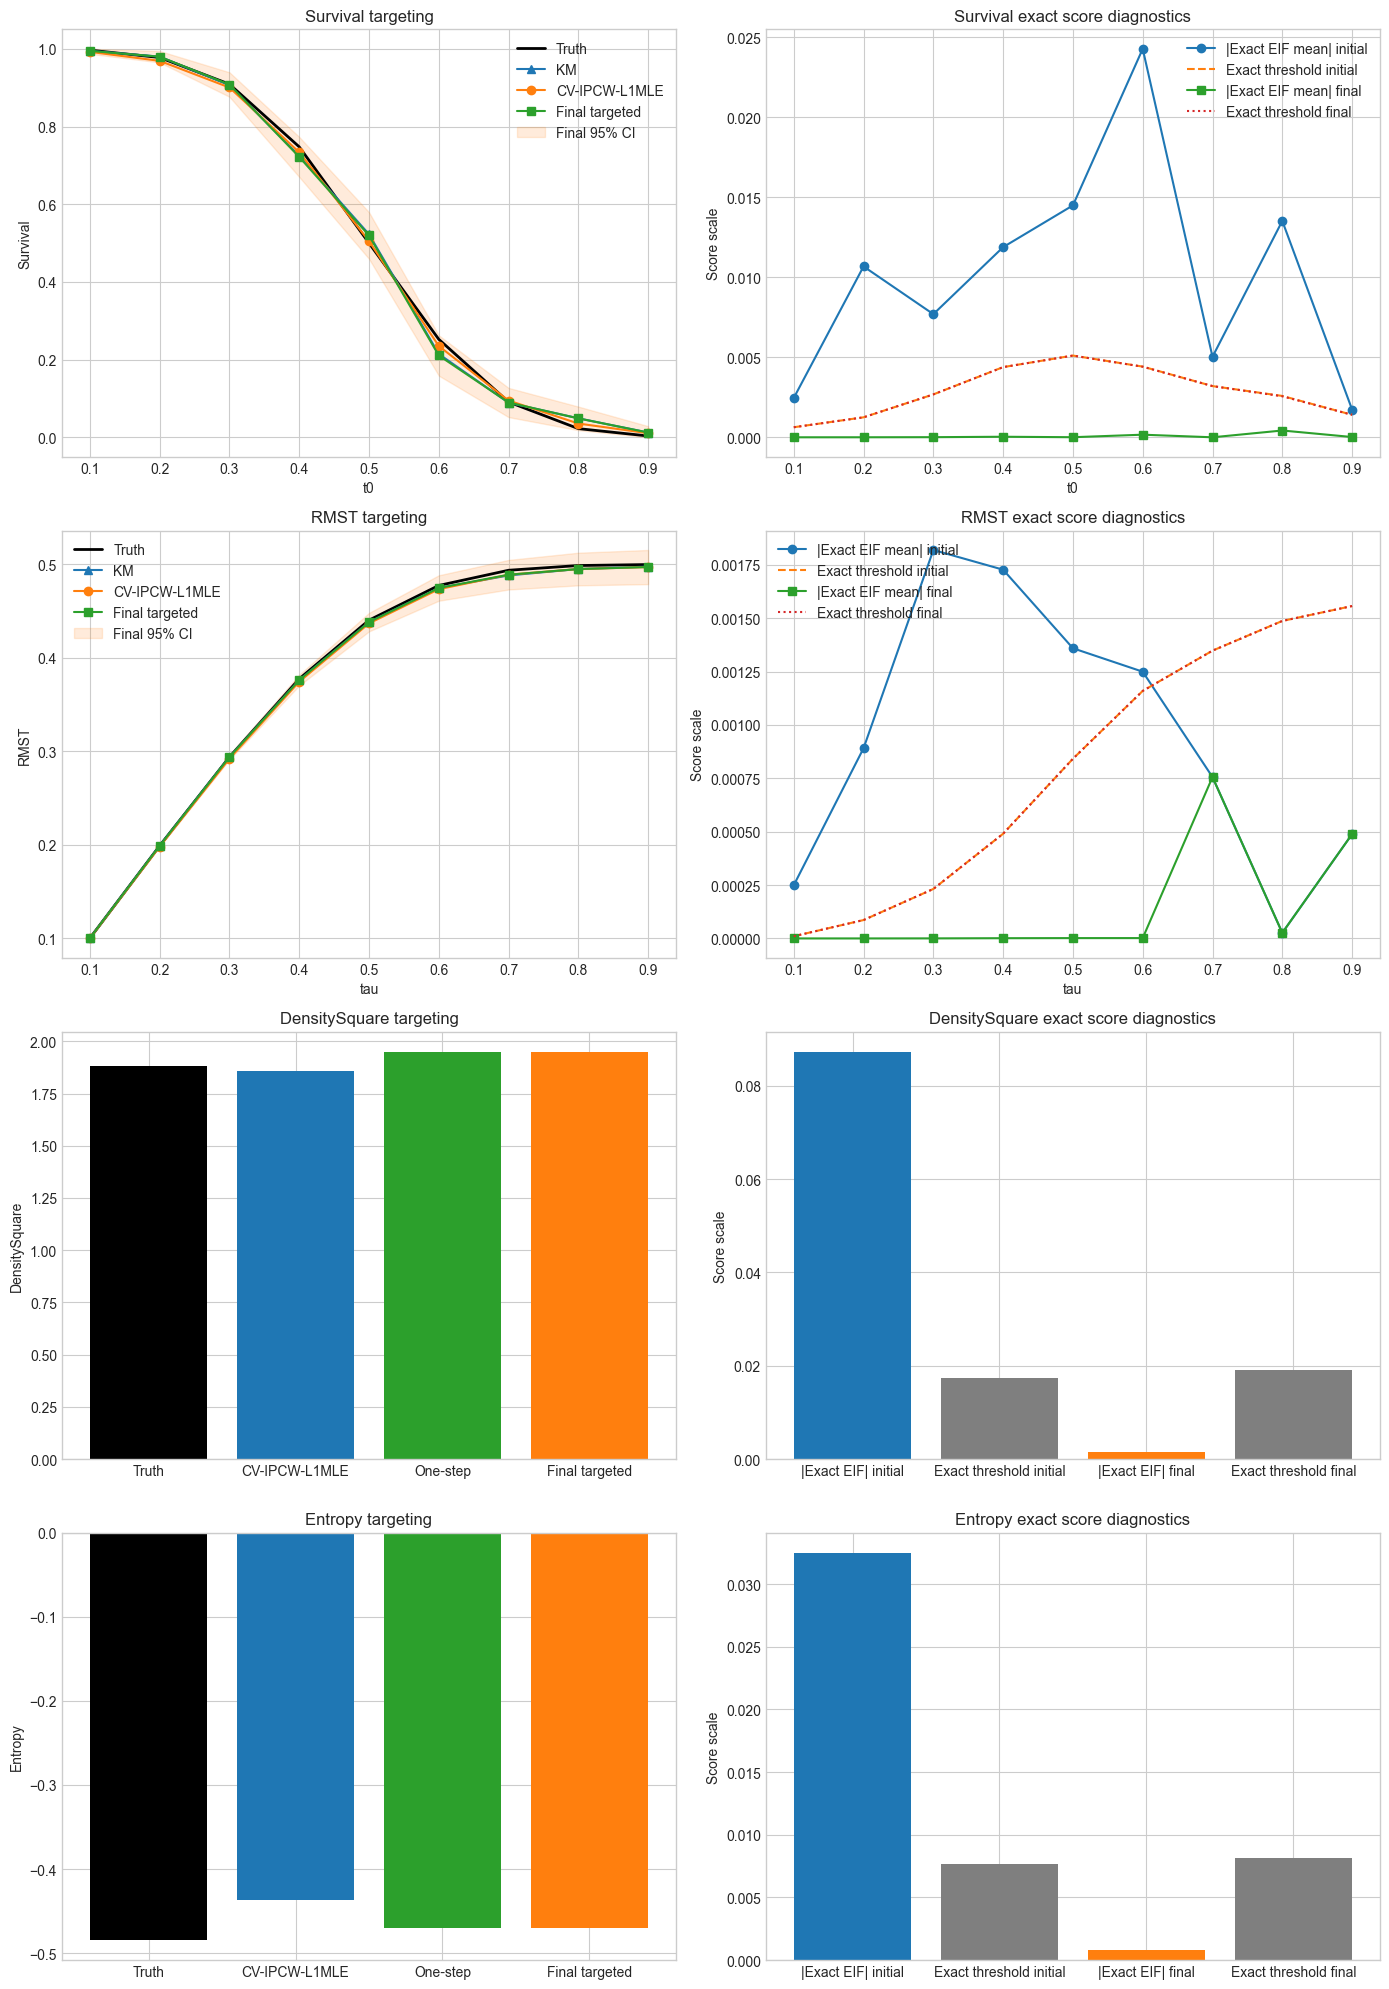

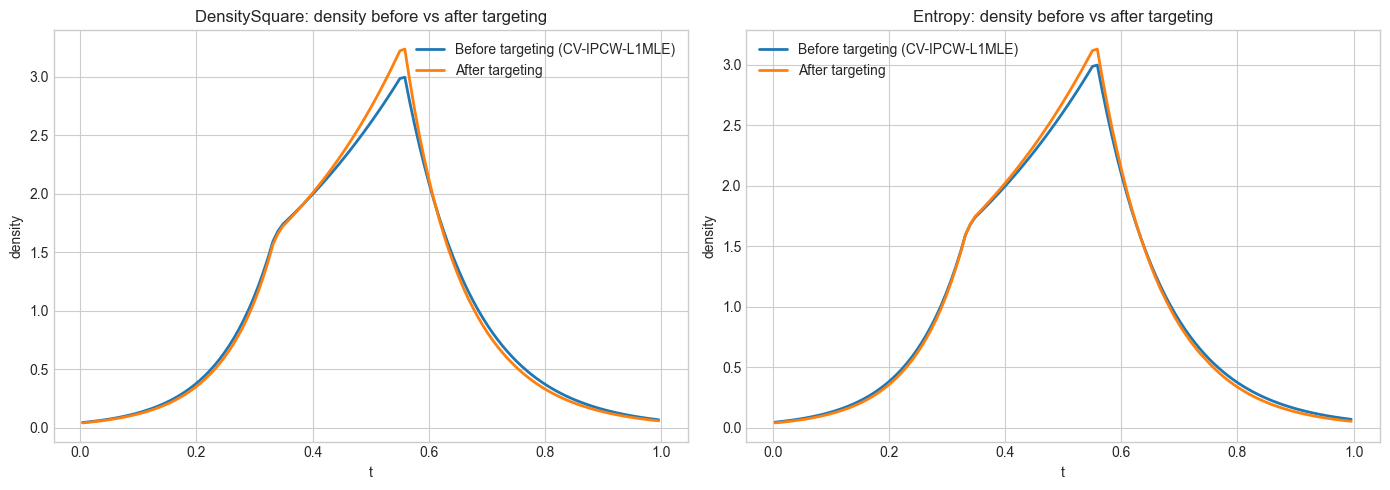

In [10]:
if all_target_demo is not None:
    fig, axes = plt.subplots(4, 2, figsize=(14, 20))
    for row_idx, target_name in enumerate(demo.TARGET_OPTIONS):
        result = all_target_demo[target_name]
        demo.plot_target_estimates(target_name, result['augmented_summary'], ax=axes[row_idx, 0])
        demo.plot_score_diagnostics(target_name, result['augmented_summary'], ax=axes[row_idx, 1])
    plt.tight_layout()
    plt.show()

    scalar_targets = ('DensitySquare', 'Entropy')
    fig, scalar_axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, target_name in zip(np.atleast_1d(scalar_axes), scalar_targets):
        fit_row = all_target_demo[target_name]['targeted_fit']['pointwise_fits'][0]
        required_keys = {'grid_midpoints', 'density_before_grid', 'estimated_density'}
        if not required_keys.issubset(fit_row.keys()):
            ax.text(
                0.5,
                0.5,
                'Density arrays are unavailable.\nRerun the previous cell first.',
                ha='center',
                va='center',
                transform=ax.transAxes,
            )
            ax.set_title(f'{target_name}: density before vs after targeting')
            ax.set_axis_off()
            continue

        grid = np.asarray(fit_row['grid_midpoints'], dtype=float)
        density_before = np.asarray(fit_row['density_before_grid'], dtype=float)
        density_after = np.asarray(fit_row['estimated_density'], dtype=float)

        ax.plot(grid, density_before, linewidth=2, label='Before targeting (CV-IPCW-L1MLE)')
        ax.plot(grid, density_after, linewidth=2, label='After targeting')
        ax.set_xlabel('t')
        ax.set_ylabel('density')
        ax.set_title(f'{target_name}: density before vs after targeting')
        ax.legend(loc='best')

    plt.tight_layout()
    plt.show()


## All Four Monte Carlo Checks

This runs the same small MC template for all four targets. Survival and RMST reuse the same grid. Density-square and entropy are scalar summaries.


In [11]:
all_target_mc = None
if RUN_ALL_TARGET_MC and MC_REPS > 0:
    all_target_mc = demo.run_all_target_small_mc(
        n_reps=MC_REPS,
        n=MC_N,
        base_seed=MC_BASE_SEED,
        shared_grid=TARGET_GRID,
        simulation_kwargs=SIMULATION_KWARGS,
        initial_fit_kwargs=MC_INITIAL_FIT_KWARGS,
        targeting_options=TARGETING_OPTIONS,
        n_workers=MC_N_WORKERS,
        show_progress=MC_SHOW_PROGRESS,
    )
    display(demo.mc_metric_overview(all_target_mc))
    display(_summarize_all_target_mc_mean_score(all_target_mc))

    targeting_usage = _summarize_targeting_usage(all_target_mc)
    if not targeting_usage.empty:
        print('TMLE targeting usage by seed:')
        display(targeting_usage)

    survival_positivity = _summarize_survival_positivity_issues(all_target_mc)
    if not survival_positivity.empty:
        print('Survival positivity issues by t0:')
        display(survival_positivity)
else:
    print('Set RUN_ALL_TARGET_MC = True and MC_REPS > 0 to run the all-target MC section.')


All-target MC:   0%|          | 0/100 [00:00<?, ?it/s]/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(
/Users/houyilong/GitHub/HALDensity/.venv/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adj

,target_type,stage,t0,tau,target,bias,variance,mse,oracle_coverage,n_replicates
0,Survival,km,0.1,NaN,NaN,-0.000384,9.008614e-06,9.065810e-06,0.95,100
1,Survival,initial,0.1,NaN,NaN,-0.011916,5.240981e-04,6.608371e-04,0.87,100
2,Survival,final,0.1,NaN,NaN,-0.000266,8.738648e-06,8.721872e-06,0.96,100
3,Survival,km,0.2,NaN,NaN,-0.000440,5.482966e-05,5.447467e-05,0.93,100
4,Survival,initial,0.2,NaN,NaN,-0.022436,1.950324e-03,2.434209e-03,0.87,100
5,Survival,final,0.2,NaN,NaN,-0.000057,5.319043e-05,5.266182e-05,0.93,100
6,Survival,km,0.3,NaN,NaN,0.002692,2.224697e-04,2.274942e-04,0.94,100
7,Survival,initial,0.3,NaN,NaN,-0.024231,2.926234e-03,3.484091e-03,0.87,100
8,Survival,final,0.3,NaN,NaN,0.003641,2.129701e-04,2.240937e-04,0.94,100
9,Survival,km,0.4,NaN,NaN,-0.000012,5.647145e-04,5.590675e-04,0.94,100


,target_type,stage,mean_score,n_replicates,t0,tau,target
0,Survival,initial,0.011663,100,0.1,NaN,NaN
1,Survival,one_step,0.000013,100,0.1,NaN,NaN
2,Survival,final,0.000013,100,0.1,NaN,NaN
3,Survival,initial,0.022383,100,0.2,NaN,NaN
4,Survival,one_step,0.000008,100,0.2,NaN,NaN
5,Survival,final,0.000008,100,0.2,NaN,NaN
6,Survival,initial,0.027828,100,0.3,NaN,NaN
7,Survival,one_step,-0.000033,100,0.3,NaN,NaN
8,Survival,final,-0.000033,100,0.3,NaN,NaN
9,Survival,initial,0.014961,100,0.4,NaN,NaN


TMLE targeting usage by seed:


,target_type,coordinate,coordinate_value,n_seeds,n_targeted,n_skipped_initial_gate,targeted_rate,mean_n_iterations
0,DensitySquare,target,DensitySquare,100,76,24,0.76,0.89
1,Entropy,target,Entropy,100,94,6,0.94,1.89
2,RMST,tau,0.1,100,88,12,0.88,6.56
3,RMST,tau,0.2,100,91,9,0.91,1.04
4,RMST,tau,0.3,100,93,7,0.93,0.93
5,RMST,tau,0.4,100,75,25,0.75,0.75
6,RMST,tau,0.5,100,53,47,0.53,0.53
7,RMST,tau,0.6,100,40,60,0.40,0.40
8,RMST,tau,0.7,100,18,82,0.18,0.18
9,RMST,tau,0.8,100,12,88,0.12,0.12


Survival positivity issues by t0:


,t0,n_seeds,n_with_positivity_issue,positivity_issue_rate,n_with_t0_gbar_clipping,n_with_jump_gbar_clipping
0,0.1,100,0,0.00,0,0
1,0.2,100,0,0.00,0,0
2,0.3,100,0,0.00,0,0
3,0.4,100,0,0.00,0,0
4,0.5,100,0,0.00,0,0
5,0.6,100,0,0.00,0,0
6,0.7,100,0,0.00,0,0
7,0.8,100,1,0.01,1,1
8,0.9,100,10,0.10,10,10


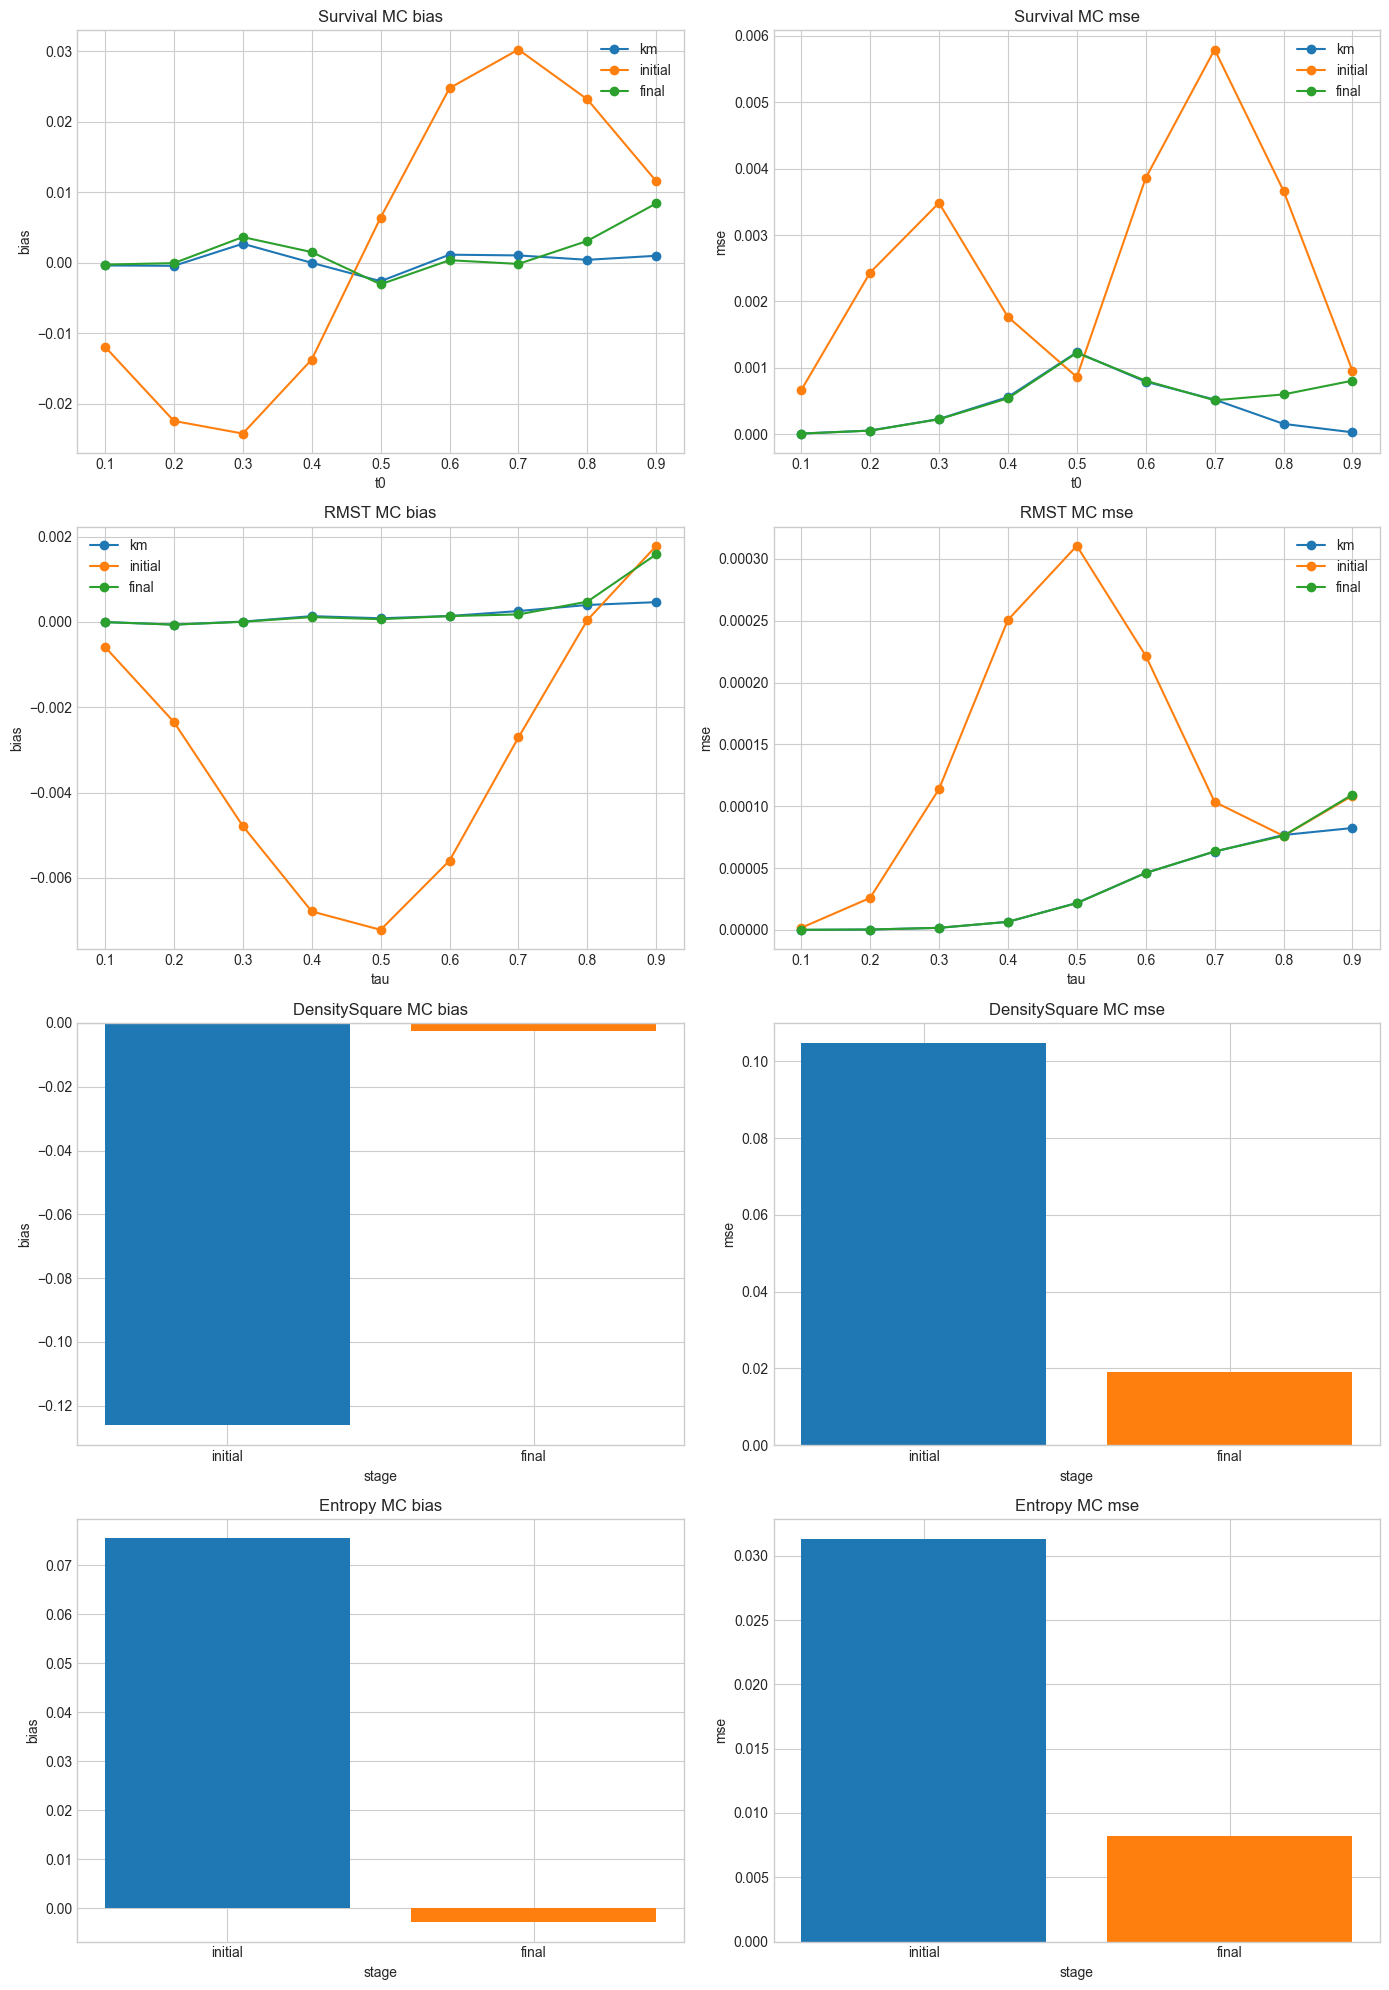

In [12]:
if all_target_mc is not None:
    fig, axes = plt.subplots(4, 2, figsize=(14, 20))
    for row_idx, target_name in enumerate(demo.TARGET_OPTIONS):
        target_metrics = all_target_mc['by_target'][target_name]['metrics']
        demo.plot_mc_metrics(target_name, target_metrics, metric='bias', ax=axes[row_idx, 0])
        demo.plot_mc_metrics(target_name, target_metrics, metric='mse', ax=axes[row_idx, 1])
    plt.tight_layout()
    plt.show()
